Dans cette partie, on va faire un contrôle du surapprentissage des trois modèles audio. On compare les trois modèles de sons généraux, sur l'audio seulement:
- **AST** (b1) : vecteur de 768 nombres ;
- **CLAP** (b2) : vecteur audio de 512 nombres ;
- **Whisper** (b3) : moyenne des 7 couches de l'encodeur, 512 nombres (représentation retenue sur le dev dans b3) ;
- **fusion tardive AST + Whisper**, notre meilleure configuration audio sur le test (b3).

Un modèle surapprend quand il apprend par coeur les exemples d'entraînement au lieu de règles générales : il est alors très bon sur le train et nettement moins bon sur des données nouvelles. On le vérifie de cinq façons, pour chaque modèle :

1. **Train / dev / test** : écart entre le score sur les données d'apprentissage et sur des données nouvelles ;
2. **Courbe de validation** : score train et dev en fonction de la régularisation `C` ;
3. **Courbe d'apprentissage** : score en fonction de la quantité de films d'entraînement ;
4. **Validation croisée par films** sur train + dev (5 découpages) : score moyen ± écart-type, pour comparer les modèles **sans utiliser le test** ;
5. **Test de permutation** : avec des étiquettes mélangées au hasard, le score doit retomber au niveau du hasard (sinon, il y aurait une fuite d'information).


## 0. Préparation

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    CODE = Path("/content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain")
else:
    CODE = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "audio" / "ghislain" / "utils.py").exists()) / "audio" / "ghislain"
sys.path.insert(0, str(CODE))

import importlib
import utils
importlib.reload(utils)

P = utils.setup(parts=("annotation",))      # métadonnées (partition, émotions, parole) + vecteurs déjà calculés

Mounted at /content/drive
Copie du zip depuis le Drive (~2-3 min)...
$ cp "/content/drive/MyDrive/Projet Multimédia/PROJET_SID_2026.zip" /content/PROJET_SID_2026.zip
Décompression de : annotation
$ mkdir -p /content/data && unzip -q -o /content/PROJET_SID_2026.zip 'PROJET_SID_2026/movie/annotation/*' -d /content/data
Données  : /content/data/PROJET_SID_2026
Résultats: /content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain


In [2]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Test rapide : mettre par ex. 20 (extraits par ensemble). None = tous les extraits.
ECHANTILLON = None

meta = utils.load_metadata(P)
SUFFIXE = ""
if ECHANTILLON:
    meta = (pd.concat([meta[meta.split == s].sample(ECHANTILLON, random_state=utils.SEED)
                       for s in utils.SPLITS]).sort_values("video_id").reset_index(drop=True))
    SUFFIXE = "_echantillon"
tr, dv, te = ((meta.split == s).to_numpy() for s in utils.SPLITS)
y = meta.label.to_numpy()
ids = meta.video_id.tolist()

X_ast = utils.load_features("ast" + SUFFIXE, P, ids)[:, :768]
X_clap = utils.load_features("clap" + SUFFIXE, P, ids)
Zw = utils.load_features("whisper_base" + SUFFIXE, P, ids)
X_whisper = Zw.reshape(len(Zw), -1, 512).mean(1)           # moyenne des 7 couches (choix de b3)

MODELES = {"AST": X_ast, "CLAP": X_clap, "Whisper": X_whisper}
COULEURS = {"AST": "#1e3a8a", "CLAP": "#0f766e", "Whisper": "#b45309"}
f1 = lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
print(len(meta), "extraits |", {n: X.shape[1] for n, X in MODELES.items()}, "descripteurs")

3088 extraits | {'AST': 768, 'CLAP': 512, 'Whisper': 512} descripteurs


## 1. Score sur le train, le dev et le test

Chaque classifieur est réglé comme dans b1, b2 et b3 (`C` choisi sur le dev avec la règle de tolérance de `utils.select_C`). On mesure son F1 macro **sur les données qui ont servi à l'entraîner** (train) et sur des données **jamais vues** (dev, test).

Pour la **fusion tardive AST + Whisper**, on fait la moyenne pondérée des probabilités des deux classifieurs, avec des poids choisis sur le dev.

In [3]:
classifieurs, C_choisi, probas, lignes = {}, {}, {}, []
for nom, X in MODELES.items():
    clf, C, _ = utils.select_C(X[tr], y[tr], X[dv], y[dv])
    classifieurs[nom], C_choisi[nom] = clf, C
    probas[nom] = {s: clf.predict_proba(X[m]) for s, m in (("train", tr), ("dev", dv), ("test", te))}
    lignes.append({"modèle": nom, "C": C, **{s: f1(y[m], probas[nom][s].argmax(1))
                                            for s, m in (("train", tr), ("dev", dv), ("test", te))}})

POIDS, _ = utils.select_weights([probas["AST"]["dev"], probas["Whisper"]["dev"]], y[dv])
fusion = lambda s: utils.fuse([probas["AST"][s], probas["Whisper"][s]], POIDS)
lignes.append({"modèle": f"fusion tardive AST + Whisper ({POIDS[0]} / {POIDS[1]})", "C": "-",
               **{s: f1(y[m], fusion(s).argmax(1)) for s, m in (("train", tr), ("dev", dv), ("test", te))}})

ecarts = pd.DataFrame(lignes).set_index("modèle")
ecarts["écart train - dev"] = ecarts.train - ecarts.dev
ecarts["écart dev - test"] = ecarts.dev - ecarts.test
display(ecarts.round(3))

,C,train,dev,test,écart train - dev,écart dev - test
modèle,,,,,,
AST,0.0001,0.338,0.236,0.248,0.101,-0.012
CLAP,0.0001,0.304,0.257,0.221,0.047,0.036
Whisper,0.003,0.483,0.310,0.254,0.173,0.056
fusion tardive AST + Whisper (0.5 / 0.5),-,0.471,0.319,0.267,0.152,0.053


## 2. Courbe de validation : le rôle de la régularisation `C`

Plus `C` est **petit**, plus le classifieur est **contraint** (il ne peut pas « coller » aux exemples) ; plus `C` est **grand**, plus il peut apprendre par cœur. Le surapprentissage se voit quand le score **train monte** alors que le score **dev baisse**. Le trait pointillé indique le `C` choisi pour chaque modèle.

train                   dev               
modèle    AST   CLAP Whisper    AST   CLAP Whisper
C                                                 
0.0001  0.338  0.304   0.306  0.236  0.257   0.240
0.0003  0.380  0.332   0.348  0.237  0.257   0.251
0.0010  0.452  0.368   0.407  0.239  0.243   0.291
0.0030  0.553  0.395   0.483  0.246  0.231   0.310
0.0100  0.664  0.452   0.558  0.233  0.230   0.306
0.0300  0.784  0.514   0.646  0.210  0.236   0.282
0.1000  0.895  0.582   0.733  0.205  0.228   0.242
1.0000  0.996  0.718   0.877  0.185  0.215   0.208

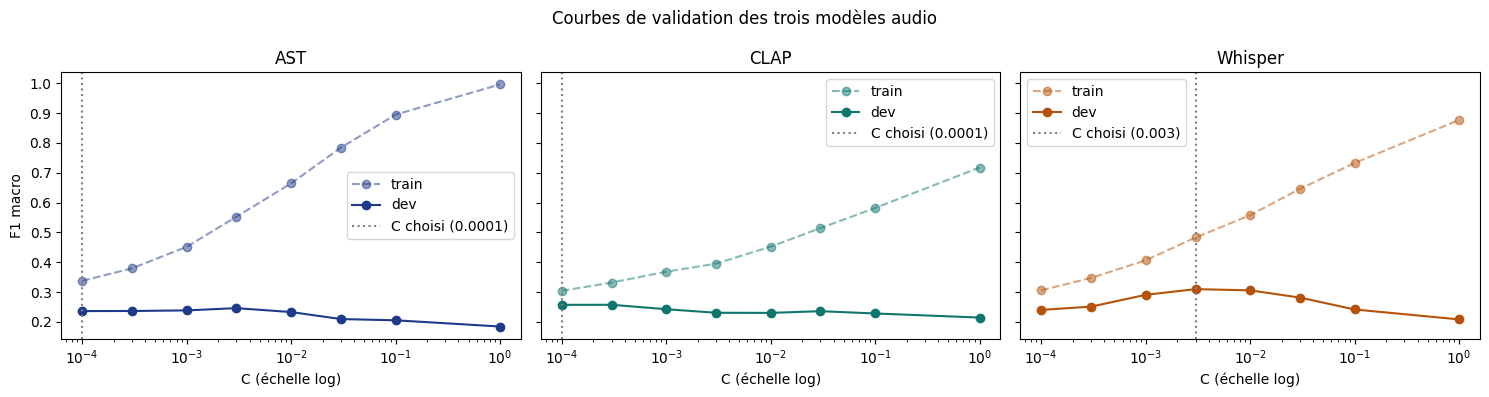

In [4]:
Cs = list(utils.CS_DEFAUT)
courbes = []
for nom, X in MODELES.items():
    for C in Cs:
        m = utils.train_classifier(X[tr], y[tr], C=C)
        courbes.append({"modèle": nom, "C": C, "train": f1(y[tr], m.predict(X[tr])), "dev": f1(y[dv], m.predict(X[dv]))})
courbes = pd.DataFrame(courbes)
display(courbes.pivot(index="C", columns="modèle", values=["train", "dev"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, nom in zip(axes, MODELES):
    d = courbes[courbes["modèle"] == nom]
    ax.semilogx(d.C, d.train, "o--", color=COULEURS[nom], alpha=0.5, label="train")
    ax.semilogx(d.C, d.dev, "o-", color=COULEURS[nom], label="dev")
    ax.axvline(C_choisi[nom], ls=":", color="gray", label=f"C choisi ({C_choisi[nom]})")
    ax.set(title=nom, xlabel="C (échelle log)")
    ax.legend()
axes[0].set_ylabel("F1 macro")
fig.suptitle("Courbes de validation des trois modèles audio")
fig.tight_layout()
fig.savefig(P.FIGS / f"surapprentissage_audio_courbe_validation{SUFFIXE}.png", dpi=150)
plt.show()

## 3. Courbe d'apprentissage : que se passe-t-il avec plus de données ?

On entraîne chaque classifieur (avec son `C` choisi) sur une partie croissante des **films** du train (10 % à 100 %, 3 tirages à chaque fois) et on mesure le score sur le train utilisé et sur le dev. Si l'écart train - dev **se réduit** quand on ajoute des données et que le dev **continue de monter**, le modèle n'est pas bloqué par le surapprentissage et profiterait de plus de données.

extraits          train           dev       
                            mean     std   mean    std   mean    std
modèle  part des films                                              
AST     0.10             205.667  23.245  0.531  0.010  0.152  0.009
        0.25             534.000  30.790  0.427  0.020  0.196  0.031
        0.50            1114.000  54.525  0.368  0.014  0.226  0.019
        0.75            1663.667  10.214  0.354  0.005  0.239  0.007
        1.00            2207.000     NaN  0.338    NaN  0.236    NaN
CLAP    0.10             205.667  23.245  0.415  0.027  0.164  0.011
        0.25             534.000  30.790  0.380  0.045  0.182  0.017
        0.50            1114.000  54.525  0.324  0.008  0.216  0.024
        0.75            1663.667  10.214  0.325  0.014  0.240  0.014
        1.00            2207.000     NaN  0.304    NaN  0.257    NaN
Whisper 0.10             205.667  23.245  0.707  0.002  0.192  0.032
        0.25             534.000  30.790  0.616  0.031  0.218  0.041
        0.50            1114.000  54.525  0.525  0.017  0.261  0.013
        0.75            1663.667  10.214  0.506  0.006  0.285  0.011
        1.00            2207.000     NaN  0.483    NaN  0.310    NaN

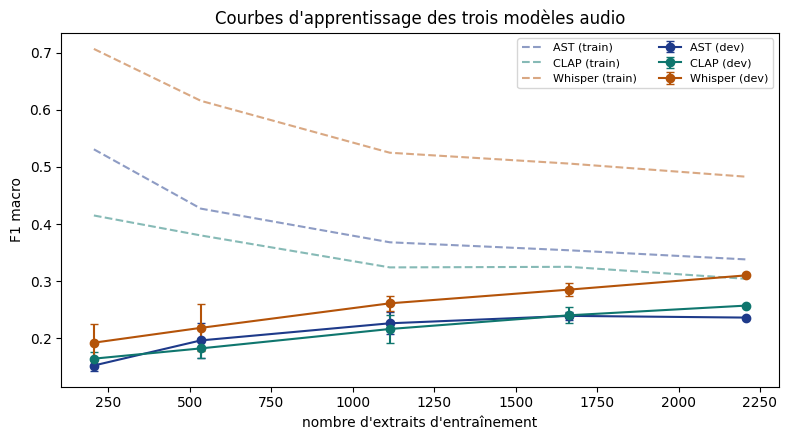

In [5]:
films_train = meta.loc[tr, "film_id"].unique()
apprentissage = []
for nom, X in MODELES.items():
    rng = np.random.default_rng(utils.SEED)                # mêmes tirages de films pour les trois modèles
    for frac in (0.1, 0.25, 0.5, 0.75, 1.0):
        for tirage in range(3 if frac < 1 else 1):
            films = rng.choice(films_train, size=max(2, int(frac * len(films_train))), replace=False)
            sous = tr & meta.film_id.isin(films).to_numpy()
            if len(np.unique(y[sous])) < 2:
                continue
            m = utils.train_classifier(X[sous], y[sous], C=C_choisi[nom])
            apprentissage.append({"modèle": nom, "part des films": frac, "extraits": int(sous.sum()),
                                  "train": f1(y[sous], m.predict(X[sous])), "dev": f1(y[dv], m.predict(X[dv]))})
apprentissage = pd.DataFrame(apprentissage).groupby(["modèle", "part des films"]).agg(["mean", "std"]).round(3)
display(apprentissage)

fig, ax = plt.subplots(figsize=(8, 4.5))
for nom in MODELES:
    d = apprentissage.loc[nom]
    x = d[("extraits", "mean")]
    ax.errorbar(x, d[("dev", "mean")], yerr=d[("dev", "std")].fillna(0), marker="o", capsize=3,
                color=COULEURS[nom], label=f"{nom} (dev)")
    ax.plot(x, d[("train", "mean")], "--", color=COULEURS[nom], alpha=0.5, label=f"{nom} (train)")
ax.set(xlabel="nombre d'extraits d'entraînement", ylabel="F1 macro",
       title="Courbes d'apprentissage des trois modèles audio")
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig(P.FIGS / f"surapprentissage_audio_courbe_apprentissage{SUFFIXE}.png", dpi=150)
plt.show()

## 4. Validation croisée par films sur train + dev : quel est le bon modèle ?

Une seule mesure sur le dev (442 extraits) est fragile. On regroupe **train + dev** (300 films) et on fait **5 découpages** : à chaque fois, on entraîne sur 4/5 des films et on évalue sur le 1/5 restant (**aucun film n'est à la fois en apprentissage et en évaluation**). Pour chaque modèle, `C` est choisi sur la moyenne des 5 découpages, avec la même règle de tolérance que `utils.select_C` (le plus petit `C` à moins de 0,01 du meilleur score).

On compare aussi les **fusions AST + Whisper** : précoce (vecteurs mis bout à bout) et tardive (moyenne des probabilités, avec les poids choisis à la section 1).

On obtient un **score moyen ± écart-type** : si deux modèles ont des moyennes qui diffèrent de moins d'un écart-type, on ne peut pas les départager. **Le test n'est pas utilisé.**

AST                              C = 0.0003  F1 = 0.237 ± 0.023   plis : [0.249 0.236 0.237 0.196 0.267]
CLAP                             C = 0.0001  F1 = 0.234 ± 0.034   plis : [0.232 0.231 0.197 0.214 0.297]
Whisper                          C = 0.001   F1 = 0.247 ± 0.035   plis : [0.252 0.27  0.224 0.195 0.295]
fusion précoce AST + Whisper     C = 0.0001  F1 = 0.242 ± 0.032   plis : [0.251 0.251 0.215 0.201 0.293]
fusion tardive AST + Whisper                 F1 = 0.250 ± 0.028   plis : [0.255 0.257 0.243 0.203 0.29 ]


,C,F1 macro moyen,écart-type,min,max
configuration,,,,,
AST,0.0003,0.237,0.023,0.196,0.267
CLAP,0.0001,0.234,0.034,0.197,0.297
Whisper,0.001,0.247,0.035,0.195,0.295
fusion précoce AST + Whisper,0.0001,0.242,0.032,0.201,0.293
fusion tardive AST + Whisper (0.5 / 0.5),-,0.250,0.028,0.203,0.290


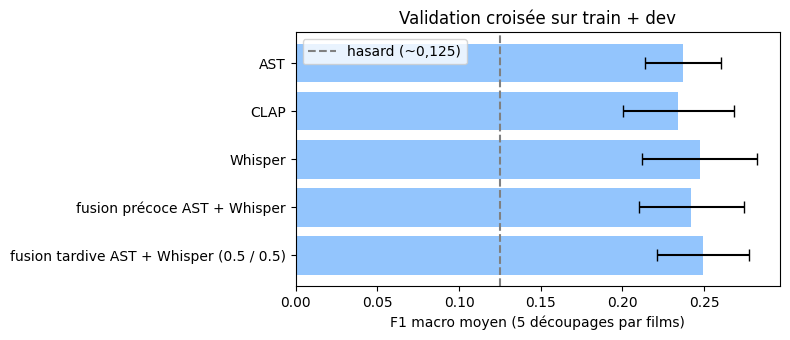

In [6]:
from sklearn.model_selection import StratifiedGroupKFold

trdv = tr | dv
groupes = meta.film_id.to_numpy()[trdv]
plis = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=utils.SEED)
            .split(np.zeros(trdv.sum()), y[trdv], groupes))
Cs_cv = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
ya = y[trdv]


def cv_probas(X, C):
    """Probabilités de validation croisée : chaque extrait est prédit par le modèle qui ne l'a pas vu."""
    p = np.zeros((len(ya), len(utils.EMOTIONS)))
    for a, v in plis:
        p[v] = utils.train_classifier(X[a], ya[a], C=C).predict_proba(X[v])
    return p


def scores_par_pli(p):
    return np.array([f1(ya[v], p[v].argmax(1)) for _, v in plis])


CONFIGS_CV = dict(MODELES)
CONFIGS_CV["fusion précoce AST + Whisper"] = np.hstack([X_ast, X_whisper])
lignes, p_cv = [], {}
for nom, X in CONFIGS_CV.items():
    Xa = X[trdv]
    par_C = {C: cv_probas(Xa, C) for C in Cs_cv}
    moy = {C: scores_par_pli(p).mean() for C, p in par_C.items()}
    C_best = min(C for C in Cs_cv if moy[C] >= max(moy.values()) - 0.01)
    p_cv[nom] = par_C[C_best]
    s = scores_par_pli(p_cv[nom])
    lignes.append({"configuration": nom, "C": C_best, "F1 macro moyen": s.mean(), "écart-type": s.std(),
                   "min": s.min(), "max": s.max()})
    print(f"{nom:32s} C = {C_best:<7} F1 = {s.mean():.3f} ± {s.std():.3f}   plis : {np.round(s, 3)}")

s = scores_par_pli(utils.fuse([p_cv["AST"], p_cv["Whisper"]], POIDS))
lignes.append({"configuration": f"fusion tardive AST + Whisper ({POIDS[0]} / {POIDS[1]})", "C": "-",
               "F1 macro moyen": s.mean(), "écart-type": s.std(), "min": s.min(), "max": s.max()})
print(f"{'fusion tardive AST + Whisper':32s} {'':11s} F1 = {s.mean():.3f} ± {s.std():.3f}   plis : {np.round(s, 3)}")

cv = pd.DataFrame(lignes).set_index("configuration")
display(cv.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(cv.index[::-1], cv["F1 macro moyen"][::-1], xerr=cv["écart-type"][::-1], capsize=4, color="#93c5fd")
ax.axvline(1 / len(utils.EMOTIONS), ls="--", color="gray", label="hasard (~0,125)")
ax.set(xlabel="F1 macro moyen (5 découpages par films)", title="Validation croisée sur train + dev")
ax.legend()
fig.tight_layout()
fig.savefig(P.FIGS / f"surapprentissage_audio_validation_croisee{SUFFIXE}.png", dpi=150)
plt.show()

## 5. Test de permutation : y a-t-il une fuite d'information ?

On **mélange au hasard les émotions** des extraits du train, on réentraîne, et on évalue sur le dev. Le modèle ne peut alors rien apprendre de réel : son score doit tomber au niveau du hasard (~0,12). Si ce n'était pas le cas, cela voudrait dire qu'il exploite une information qui ne devrait pas être disponible (fuite).

In [7]:
permutation = []
for nom, X in MODELES.items():
    f1_perm = [f1(y[dv], utils.train_classifier(X[tr], np.random.default_rng(k).permutation(y[tr]),
                                                C=C_choisi[nom]).predict(X[dv])) for k in range(5)]
    permutation.append({"modèle": nom, "F1 dev (vraies étiquettes)": f1(y[dv], probas[nom]["dev"].argmax(1)),
                        "F1 dev (étiquettes mélangées)": np.mean(f1_perm), "écart-type": np.std(f1_perm)})
display(pd.DataFrame(permutation).set_index("modèle").round(3))

,F1 dev (vraies étiquettes),F1 dev (étiquettes mélangées),écart-type
modèle,,,
AST,0.236,0.106,0.018
CLAP,0.257,0.094,0.018
Whisper,0.310,0.107,0.008


## 6. Conclusion

**1. Écart train / dev / test : Whisper surapprend le plus, mais le surapprentissage reste modéré pour les trois modèles.**
- Écart train - dev : **Whisper 0,173** (train 0,483, dev 0,310), **AST 0,101** (0,338 / 0,236), **CLAP 0,047** (0,304 / 0,257). Les scores train restent bas (≤ 0,48) grâce aux petites valeurs de `C` : aucun modèle n'apprend par cœur.
- Passage du dev au test : **AST est le plus stable** (0,236 → 0,248). CLAP perd 0,036 (0,257 → 0,221) et **Whisper perd 0,056** (0,310 → 0,254). Le score dev de Whisper est trop optimiste, car deux choix ont été faits sur le dev (la couche, puis `C`).
- La fusion tardive AST + Whisper perd aussi 0,053 (0,319 → 0,267), mais elle reste la meilleure sur le test.

**2. Courbes de validation : le `C` choisi est dans une zone stable pour les trois modèles.**
- **AST** : le dev reste presque constant (0,233 à 0,246) entre `C` = 0,0001 et 0,01. Le `C` choisi (0,0001) est le plus prudent de cette zone.
- **CLAP** : le meilleur dev (0,257) est obtenu pour `C` = 0,0001 et 0,0003, puis il baisse. Le `C` choisi (0,0001) correspond donc au maximum.
- **Whisper** : le dev monte jusqu'à 0,310 pour `C` = 0,003 et reste à 0,306 pour 0,01, puis il baisse. Le `C` choisi est sur ce plateau.
- Au-delà de `C` = 0,03, les trois modèles montrent le surapprentissage classique : le train monte (jusqu'à 0,72 à 1,00) pendant que le dev baisse (jusqu'à 0,19 à 0,21). Les `C` choisis évitent cette zone.

**3. Courbes d'apprentissage : plus de données aiderait, surtout Whisper.**
- De 10 % à 100 % des films d'entraînement, le dev progresse pour les trois modèles : **Whisper +0,118** (0,192 → 0,310), CLAP +0,093 (0,164 → 0,257) et AST +0,084 (0,152 → 0,236).
- Whisper et CLAP **montent encore** entre 75 % et 100 %. AST semble arriver à un plateau (0,239 → 0,236).
- Dans le même temps, le score train baisse et l'écart train - dev se réduit : les modèles sont limités par la **quantité de données**, pas par le surapprentissage.

**4. Validation croisée (5 découpages par films, sans le test) : les modèles sont impossibles à départager.**

| Configuration | F1 macro moyen | écart-type |
|---|---|---|
| Fusion tardive AST + Whisper | **0,250** | 0,028 |
| Whisper | 0,247 | 0,035 |
| Fusion précoce AST + Whisper | 0,242 | 0,032 |
| AST | 0,237 | 0,023 |
| CLAP | 0,234 | 0,034 |

- La fusion tardive a le meilleur score moyen, mais l'écart entre la meilleure et la moins bonne configuration (0,016) est plus petit que l'écart-type (0,023 à 0,035). Les différences ne sont donc pas significatives.
- La validation croisée confirme que le score dev de Whisper (0,310) était trop optimiste : son score réaliste est d'environ **0,25**, proche de celui des autres modèles.

**5. Permutation : pas de fuite d'information.**
- Avec des émotions mélangées au hasard, le F1 macro du dev tombe à **0,106** pour **AST**, **0,094** pour **CLAP** et **0,107** pour **Whisper**. C'est le niveau du hasard (environ 0,125).
- Les scores obtenus avec les vraies étiquettes (0,24 à 0,31) viennent donc bien d'une information réelle dans le son.

**6. Choix final : AST.**
- **C'est le modèle le plus fiable.** C'est le seul dont le score ne baisse pas entre le dev et le test (0,236 → 0,248). Celui de CLAP baisse de 0,036 et celui de Whisper de 0,056 : leurs scores dev étaient trop optimistes.
- **C'est le plus stable.** Il a le plus petit écart-type en validation croisée (**0,023**, contre 0,034 pour CLAP et 0,035 pour Whisper), et sa courbe de validation est presque plate. Il dépend donc peu du découpage des données et du réglage de `C`.
- **Il n'est pas significativement moins bon que les autres.** En validation croisée, il obtient 0,237, contre 0,247 pour Whisper et 0,250 pour la fusion tardive. Ces écarts (≤ 0,013) sont plus petits que l'écart-type : on ne peut pas dire que les autres modèles font réellement mieux.
- **C'est le choix le plus simple et le plus honnête.** Un seul modèle, sans choix de couche sur le dev comme pour Whisper, ni réglage de poids comme pour la fusion. Il est aussi complémentaire des modèles de voix du binôme, puisqu'il analyse les **sons et la musique** plutôt que la parole.
- **Réserve :** AST semble avoir atteint un plateau (0,239 avec 75 % des films, 0,236 avec 100 %). Avec beaucoup plus de données, Whisper pourrait le dépasser, puisqu'il progresse encore.